# PulmoSight 03 — PulmoNet: a Custom CNN Trained From Scratch

In [1]:
import json, math, os, random, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.io as tvio
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
IMAGE_SIZE, MEAN, STD = 512, 0.449, 0.226
CLASSES = ["normal", "tb"]
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"Project root : {ROOT}")
print(f"PyTorch      : {torch.__version__}")
print(f"Device       : {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")
print(f"AMP dtype    : {AMP_DTYPE}")

Project root : F:\Projects\pulmoSight\TB Project
PyTorch      : 2.11.0+cu128
Device       : cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
AMP dtype    : torch.bfloat16


## Data pipeline

In [2]:
def read_xray(path):
    """Decode a cached 8-bit grayscale PNG -> uint8 tensor [1, H, W]."""
    img = tvio.decode_image(tvio.read_file(str(path)), mode=tvio.ImageReadMode.GRAY)
    if img.shape[-2:] != (IMAGE_SIZE, IMAGE_SIZE):
        img = F.interpolate(img[None].float(), size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear",
                            antialias=True, align_corners=False)[0].round().clamp(0, 255).to(torch.uint8)
    return img


class XrayLoader:
    """Thread-pool batch loader.

    Windows notebooks cannot pickle notebook-defined Datasets into DataLoader worker
    processes, so we decode PNGs with threads (decoding releases the GIL) and do all
    augmentation on the GPU instead.
    """
    def __init__(self, frame, batch_size=32, shuffle=False, drop_last=False, threads=12, prefetch=6, seed=SEED):
        self.paths = [ROOT / p for p in frame["path"]]
        self.labels = frame["label"].to_numpy(dtype=np.int64)
        self.batch_size, self.shuffle, self.drop_last = batch_size, shuffle, drop_last
        self.threads, self.prefetch = threads, prefetch
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        n = len(self.paths)
        return n // self.batch_size if self.drop_last else math.ceil(n / self.batch_size)

    def __iter__(self):
        n = len(self.paths)
        order = self.rng.permutation(n) if self.shuffle else np.arange(n)
        batches = [order[i:i + self.batch_size] for i in range(0, n, self.batch_size)]
        if self.drop_last and len(batches[-1]) < self.batch_size:
            batches = batches[:-1]
        with ThreadPoolExecutor(self.threads) as pool:
            pending, it = deque(), iter(batches)
            submit = lambda b: (b, [pool.submit(read_xray, self.paths[i]) for i in b])
            for _ in range(self.prefetch):
                b = next(it, None)
                if b is not None:
                    pending.append(submit(b))
            while pending:
                b, futures = pending.popleft()
                nxt = next(it, None)
                if nxt is not None:
                    pending.append(submit(nxt))
                x = torch.stack([f.result() for f in futures])
                yield x, torch.from_numpy(self.labels[b])


def gpu_augment(x):
    """Random affine (+-7 deg, +-4% shift, 0.93-1.07 zoom) + brightness/contrast jitter, on GPU."""
    b, dev = x.size(0), x.device
    u = lambda: torch.rand(b, device=dev) * 2 - 1
    angle, scale = u() * math.radians(7), 1 + u() * 0.07
    tx, ty = u() * 0.08, u() * 0.08            # grid spans [-1, 1] -> 4% of the image
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    bright = 1 + u().view(b, 1, 1, 1) * 0.15
    contrast = 1 + u().view(b, 1, 1, 1) * 0.15
    x = x * bright
    m = x.mean(dim=(2, 3), keepdim=True)
    return ((x - m) * contrast + m).clamp(0, 1)


def prepare_batch(x, augment=False):
    x = x.to(DEVICE, non_blocking=True).float().div_(255)
    if augment:
        x = gpu_augment(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)


splits = pd.read_csv(ROOT / "splits" / "splits.csv")
train_df = splits[splits.split == "train"].reset_index(drop=True)
val_df = splits[splits.split == "val"].reset_index(drop=True)
test_df = splits[splits.split == "test"].reset_index(drop=True)
print(splits.groupby(["split", "label"]).size().unstack().rename(columns=dict(enumerate(CLASSES))))

label  normal    tb
split              
test      861   820
train    6860  6585
val       850   809


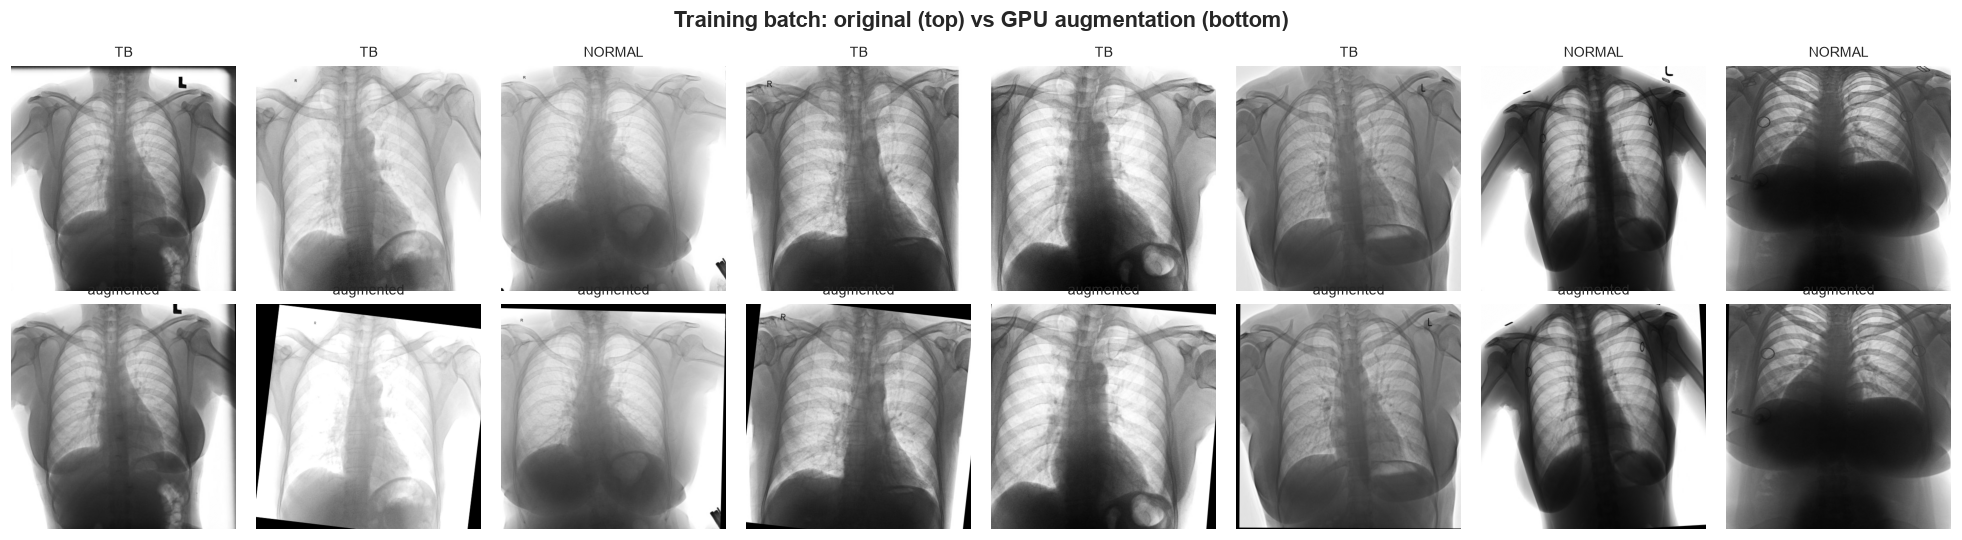

In [3]:
x, y = next(iter(XrayLoader(train_df, batch_size=8, shuffle=True)))
aug = prepare_batch(x, augment=True).float().cpu() * STD + MEAN
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for i in range(8):
    axes[0, i].imshow(x[i, 0], cmap="gray"); axes[0, i].set_title(CLASSES[y[i]].upper(), fontsize=9)
    axes[1, i].imshow(aug[i, 0].clamp(0, 1), cmap="gray"); axes[1, i].set_title("augmented", fontsize=9)
for ax in axes.flat: ax.axis("off")
plt.suptitle("Training batch: original (top) vs GPU augmentation (bottom)", weight="bold"); plt.tight_layout(); plt.show()

## The PulmoNet architecture

In [4]:
class SqueezeExcite(nn.Module):
    """Channel attention: learn which feature maps matter for this image."""
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(channels, channels // reduction, 1),
                                nn.SiLU(), nn.Conv2d(channels // reduction, channels, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x)


class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k=3, stride=1, act=True):
        super().__init__(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False), nn.BatchNorm2d(cout),
                         nn.SiLU() if act else nn.Identity())


class ResidualSEBlock(nn.Module):
    """3x3 conv -> 3x3 conv -> squeeze-excite, plus a (projected) skip connection."""
    def __init__(self, cin, cout, stride=1, drop_path=0.0):
        super().__init__()
        self.body = nn.Sequential(ConvBNAct(cin, cout, 3, stride), ConvBNAct(cout, cout, 3, act=False),
                                  SqueezeExcite(cout))
        self.skip = (nn.Identity() if stride == 1 and cin == cout else
                     nn.Sequential(nn.AvgPool2d(stride) if stride > 1 else nn.Identity(),
                                   ConvBNAct(cin, cout, 1, act=False)))
        self.drop_path = drop_path
        self.act = nn.SiLU()

    def forward(self, x):
        out = self.body(x)
        if self.training and self.drop_path > 0:   # stochastic depth
            keep = torch.rand(out.size(0), 1, 1, 1, device=out.device) >= self.drop_path
            out = out * keep / (1 - self.drop_path)
        return self.act(out + self.skip(x))


class PulmoNet(nn.Module):
    """Custom CNN for 1-channel 512x512 chest X-rays, trained from scratch.

    512 -> stem (128) -> stage1 (128) -> stage2 (64) -> stage3 (32) -> stage4 (16) -> GAP -> FC
    """
    def __init__(self, widths=(48, 96, 160, 256), depths=(2, 2, 3, 2), num_classes=2, drop=0.3, drop_path=0.1):
        super().__init__()
        self.stem = nn.Sequential(ConvBNAct(1, 32, 5, 2), ConvBNAct(32, 32, 3), ConvBNAct(32, widths[0], 3, 2))
        total, idx, cin, stages = sum(depths), 0, widths[0], []
        for i, (w, d) in enumerate(zip(widths, depths)):
            blocks = []
            for j in range(d):
                stride = 2 if (j == 0 and i > 0) else 1
                blocks.append(ResidualSEBlock(cin, w, stride, drop_path * idx / max(total - 1, 1)))
                cin, idx = w, idx + 1
            stages.append(nn.Sequential(*blocks))
        self.stage1, self.stage2, self.stage3, self.stage4 = stages
        self.head_conv = ConvBNAct(cin, 512, 1)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(drop), nn.Linear(512, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01); nn.init.zeros_(m.bias)

    def features(self, x):
        x = self.stem(x)
        x = self.stage4(self.stage3(self.stage2(self.stage1(x))))
        return self.head_conv(x)

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

In [5]:
model = PulmoNet().to(DEVICE, memory_format=torch.channels_last)

def count(m): return sum(p.numel() for p in m.parameters())
parts = {"stem": model.stem, "stage1 (128x128)": model.stage1, "stage2 (64x64)": model.stage2,
         "stage3 (32x32)": model.stage3, "stage4 (16x16)": model.stage4, "head conv": model.head_conv,
         "classifier": model.classifier}
table = pd.DataFrame({"parameters": {k: count(v) for k, v in parts.items()}})
table.loc["TOTAL"] = count(model)
display(table.style.format("{:,}"))

# Shapes through the network
with torch.no_grad():
    t = torch.zeros(1, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    for name in ["stem", "stage1", "stage2", "stage3", "stage4", "head_conv"]:
        t = getattr(model, name)(t); print(f"{name:>10}: {tuple(t.shape)}")

from torch.utils.flop_counter import FlopCounterMode
with FlopCounterMode(display=False) as fc:
    model.eval()(torch.zeros(1, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
print(f"\nGFLOPs per 512x512 image: {fc.get_total_flops() / 2e9:.2f} (multiply-adds)")

,parameters
stem,"24,064"
stage1 (128x128),"84,588"
stage2 (64x64),"300,696"
stage3 (32x32),"1,327,580"
stage4 (16x16),"2,214,976"
head conv,"132,096"
classifier,"1,026"
TOTAL,"4,085,026"


      stem: (1, 48, 128, 128)


    stage1: (1, 48, 128, 128)


    stage2: (1, 96, 64, 64)


    stage3: (1, 160, 32, 32)


    stage4: (1, 256, 16, 16)


W1113 15:58:58.848000 36724 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


 head_conv: (1, 512, 16, 16)

GFLOPs per 512x512 image: 5.38 (multiply-adds)


## Training configuration

In [6]:
def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda")


@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with autocast():
            out = model(prepare_batch(x))
        logits.append(out.float().cpu()); labels.append(y)
    return torch.cat(logits).numpy(), torch.cat(labels).numpy()


def binary_metrics(logits, labels, threshold=0.5):
    p = torch.from_numpy(logits).softmax(1)[:, 1].numpy()
    pred = p >= threshold
    pos = labels == 1
    tp, tn = int((pred & pos).sum()), int((~pred & ~pos).sum())
    fp, fn = int((pred & ~pos).sum()), int((~pred & pos).sum())
    return {"auroc": float(roc_auc_score(labels, p)), "acc": (tp + tn) / len(labels),
            "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1)}


def fit(model, train_loader, val_loader, optimizer, scheduler, epochs, criterion, ckpt_path, meta,
        patience=6, history=None, stage="", before_epoch=None):
    """Train with early stopping on validation AUROC. Saves the best checkpoint to ckpt_path."""
    history = [] if history is None else history
    best = max([h["val_auroc"] for h in history], default=-1.0)
    bad = 0
    start = len(history) + 1
    for epoch in range(start, start + epochs):
        t0 = time.time()
        model.train()
        if before_epoch:
            before_epoch(model)
        loss_sum = torch.zeros((), device=DEVICE); correct = torch.zeros((), device=DEVICE); seen = 0
        for x, y in train_loader:
            x, y = prepare_batch(x, augment=True), y.to(DEVICE, non_blocking=True)
            with autocast():
                out = model(x)
            loss = criterion(out.float(), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * y.size(0); correct += (out.argmax(1) == y).sum(); seen += y.size(0)

        val_logits, val_labels = predict_logits(model, val_loader)
        val_loss = F.cross_entropy(torch.from_numpy(val_logits), torch.from_numpy(val_labels)).item()
        m = binary_metrics(val_logits, val_labels)
        row = {"epoch": epoch, "stage": stage, "train_loss": loss_sum.item() / seen, "train_acc": correct.item() / seen,
               "val_loss": val_loss, "val_acc": m["acc"], "val_auroc": m["auroc"],
               "val_sensitivity": m["sensitivity"], "val_specificity": m["specificity"],
               "lr": optimizer.param_groups[-1]["lr"], "seconds": time.time() - t0}
        history.append(row)
        flag = ""
        if m["auroc"] > best:
            best, bad, flag = m["auroc"], 0, "  * best, saved"
            torch.save({**meta, "state_dict": model.state_dict(), "epoch": epoch, "val_metrics": m}, ckpt_path)
        else:
            bad += 1
        print(f"Epoch {epoch:02d} {stage:>9} | train loss {row['train_loss']:.4f} acc {row['train_acc']:.3f} | "
              f"val loss {val_loss:.4f} acc {m['acc']:.3f} AUROC {m['auroc']:.4f} "
              f"sens {m['sensitivity']:.3f} spec {m['specificity']:.3f} | {row['seconds']:.0f}s{flag}")
        if bad >= patience:
            print(f"Early stopping: no AUROC improvement for {patience} epochs.")
            break
    return history


def plot_history(history, title):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    axes[0].plot(h.epoch, h.train_loss, "o-", label="train"); axes[0].plot(h.epoch, h.val_loss, "o-", label="val")
    axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend()
    axes[1].plot(h.epoch, h.train_acc, "o-", label="train"); axes[1].plot(h.epoch, h.val_acc, "o-", label="val")
    axes[1].set(title="Accuracy", xlabel="epoch"); axes[1].legend()
    axes[2].plot(h.epoch, h.val_auroc, "o-", color="tab:green", label="val AUROC")
    axes[2].plot(h.epoch, h.val_sensitivity, "--", label="val sensitivity")
    axes[2].plot(h.epoch, h.val_specificity, "--", label="val specificity")
    best = h.loc[h.val_auroc.idxmax()]
    axes[2].axvline(best.epoch, color="gray", ls=":", label=f"best epoch {int(best.epoch)}")
    axes[2].set(title="Validation metrics", xlabel="epoch"); axes[2].legend()
    fig.suptitle(title, fontsize=14, weight="bold"); fig.tight_layout()
    return fig

In [7]:
CONFIG = dict(arch="pulmonet", epochs=40, batch_size=32, lr=2e-3, weight_decay=0.05,
              label_smoothing=0.05, patience=8)
RUN_DIR = ROOT / "models" / "pulmonet"
RUN_DIR.mkdir(parents=True, exist_ok=True)

seed_everything()
model = PulmoNet().to(DEVICE, memory_format=torch.channels_last)
train_loader = XrayLoader(train_df, CONFIG["batch_size"], shuffle=True, drop_last=True)
val_loader = XrayLoader(val_df, 64)

decay = [p for p in model.parameters() if p.ndim > 1]
no_decay = [p for p in model.parameters() if p.ndim <= 1]
optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": CONFIG["weight_decay"]},
                               {"params": no_decay, "weight_decay": 0.0}], lr=CONFIG["lr"])
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CONFIG["lr"], epochs=CONFIG["epochs"],
                                                steps_per_epoch=len(train_loader), pct_start=0.05)
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG["label_smoothing"])
meta = {"arch": "pulmonet", "classes": CLASSES, "image_size": IMAGE_SIZE, "mean": MEAN, "std": STD, "config": CONFIG}
print(f"Train batches/epoch: {len(train_loader)} | Val images: {len(val_df)}")

Train batches/epoch: 420 | Val images: 1659


In [8]:
t_start = time.time()
history = fit(model, train_loader, val_loader, optimizer, scheduler, CONFIG["epochs"], criterion,
              RUN_DIR / "best.pth", meta, patience=CONFIG["patience"], stage="scratch")
train_minutes = (time.time() - t_start) / 60
(RUN_DIR / "history.json").write_text(json.dumps(history, indent=2))
print(f"\nTotal training time: {train_minutes:.1f} min")

Epoch 01   scratch | train loss 0.6776 acc 0.564 | val loss 0.6742 acc 0.588 AUROC 0.6239 sens 0.375 spec 0.792 | 134s  * best, saved


Epoch 02   scratch | train loss 0.6676 acc 0.595 | val loss 0.6823 acc 0.560 AUROC 0.6668 sens 0.122 spec 0.976 | 70s  * best, saved


Epoch 03   scratch | train loss 0.6560 acc 0.612 | val loss 0.6874 acc 0.580 AUROC 0.6831 sens 0.870 spec 0.304 | 72s  * best, saved


Epoch 04   scratch | train loss 0.6328 acc 0.645 | val loss 0.6161 acc 0.688 AUROC 0.7428 sens 0.618 spec 0.754 | 71s  * best, saved


Epoch 05   scratch | train loss 0.6051 acc 0.679 | val loss 0.5515 acc 0.730 AUROC 0.8068 sens 0.553 spec 0.899 | 70s  * best, saved


Epoch 06   scratch | train loss 0.5701 acc 0.716 | val loss 0.5667 acc 0.699 AUROC 0.7946 sens 0.518 spec 0.871 | 77s


... (30 outputs left out)

Epoch 37   scratch | train loss 0.3209 acc 0.893 | val loss 0.3533 acc 0.850 AUROC 0.9226 sens 0.795 spec 0.902 | 67s


Epoch 38   scratch | train loss 0.3201 acc 0.890 | val loss 0.3489 acc 0.849 AUROC 0.9245 sens 0.842 spec 0.856 | 68s  * best, saved


Epoch 39   scratch | train loss 0.3239 acc 0.890 | val loss 0.3497 acc 0.847 AUROC 0.9232 sens 0.813 spec 0.880 | 67s


Epoch 40   scratch | train loss 0.3190 acc 0.892 | val loss 0.3477 acc 0.851 AUROC 0.9243 sens 0.837 spec 0.865 | 68s

Total training time: 47.6 min


## Learning curves

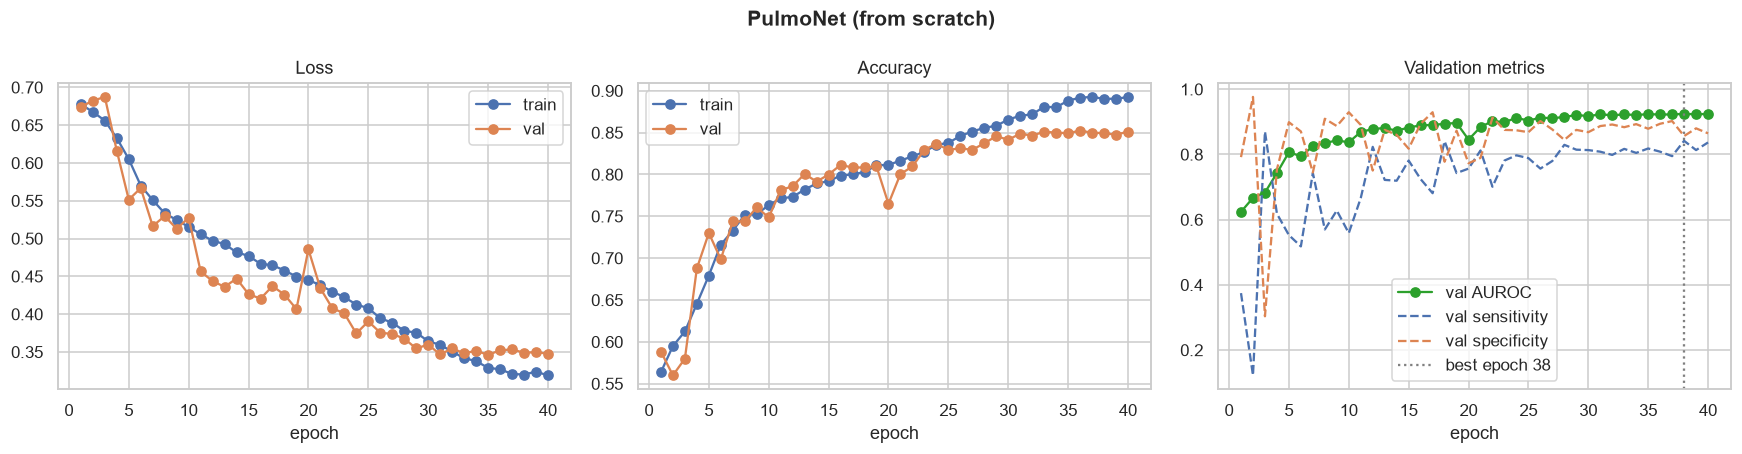

Best epoch 38: val AUROC 0.9245, acc 0.849, sens 0.842, spec 0.856


In [9]:
plot_history(history, "PulmoNet (from scratch)")
plt.savefig(RUN_DIR / "learning_curves.png", dpi=150, bbox_inches="tight"); plt.show()
best = max(history, key=lambda h: h["val_auroc"])
print(f"Best epoch {best['epoch']}: val AUROC {best['val_auroc']:.4f}, acc {best['val_acc']:.3f}, "
      f"sens {best['val_sensitivity']:.3f}, spec {best['val_specificity']:.3f}")

## Validation check of the best checkpoint

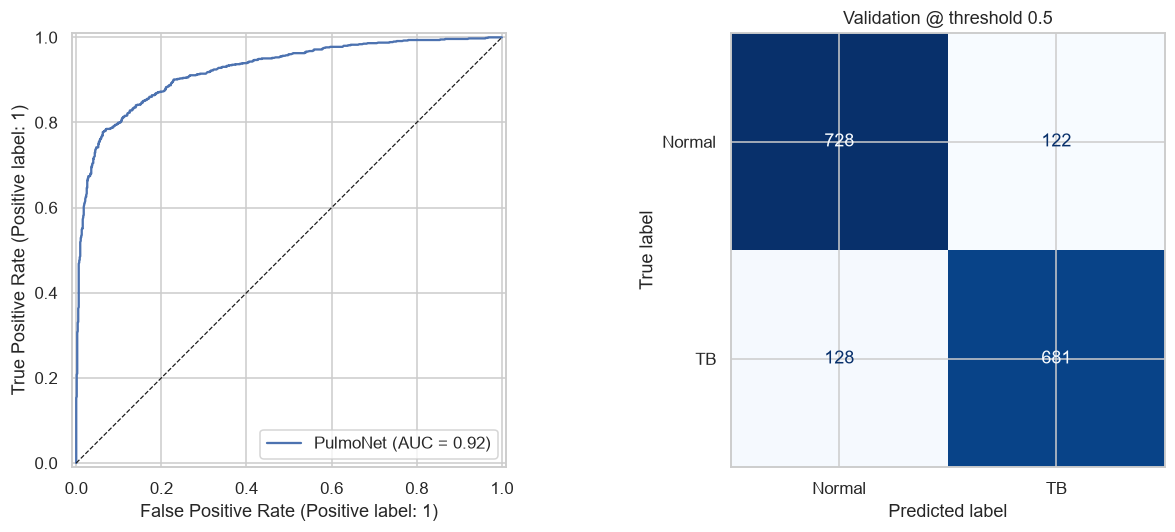

{'auroc': 0.9245284665163964, 'acc': 0.8493068113321278, 'sensitivity': 0.8417799752781211, 'specificity': 0.8564705882352941}


In [10]:
ckpt = torch.load(RUN_DIR / "best.pth", map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["state_dict"])
val_logits, val_labels = predict_logits(model, val_loader)
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
p = torch.from_numpy(val_logits).softmax(1)[:, 1].numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(val_labels, p, ax=axes[0], name="PulmoNet"); axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ConfusionMatrixDisplay.from_predictions(val_labels, p >= 0.5, display_labels=["Normal", "TB"], cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title("Validation @ threshold 0.5"); plt.tight_layout(); plt.show()
print(binary_metrics(val_logits, val_labels))

## What did the network learn?

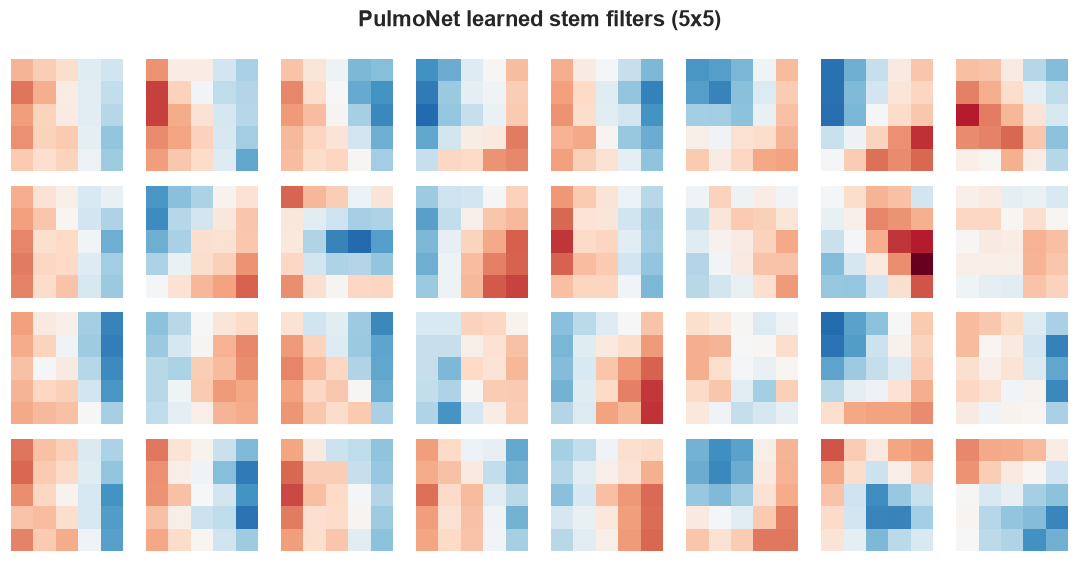

In [11]:
w = model.stem[0][0].weight.detach().float().cpu()[:, 0]
fig, axes = plt.subplots(4, 8, figsize=(10, 5.2))
for ax, k in zip(axes.flat, w):
    ax.imshow(k, cmap="RdBu_r", vmin=-w.abs().max(), vmax=w.abs().max()); ax.axis("off")
plt.suptitle("PulmoNet learned stem filters (5x5)", weight="bold"); plt.tight_layout(); plt.show()

### Feature maps at each stage

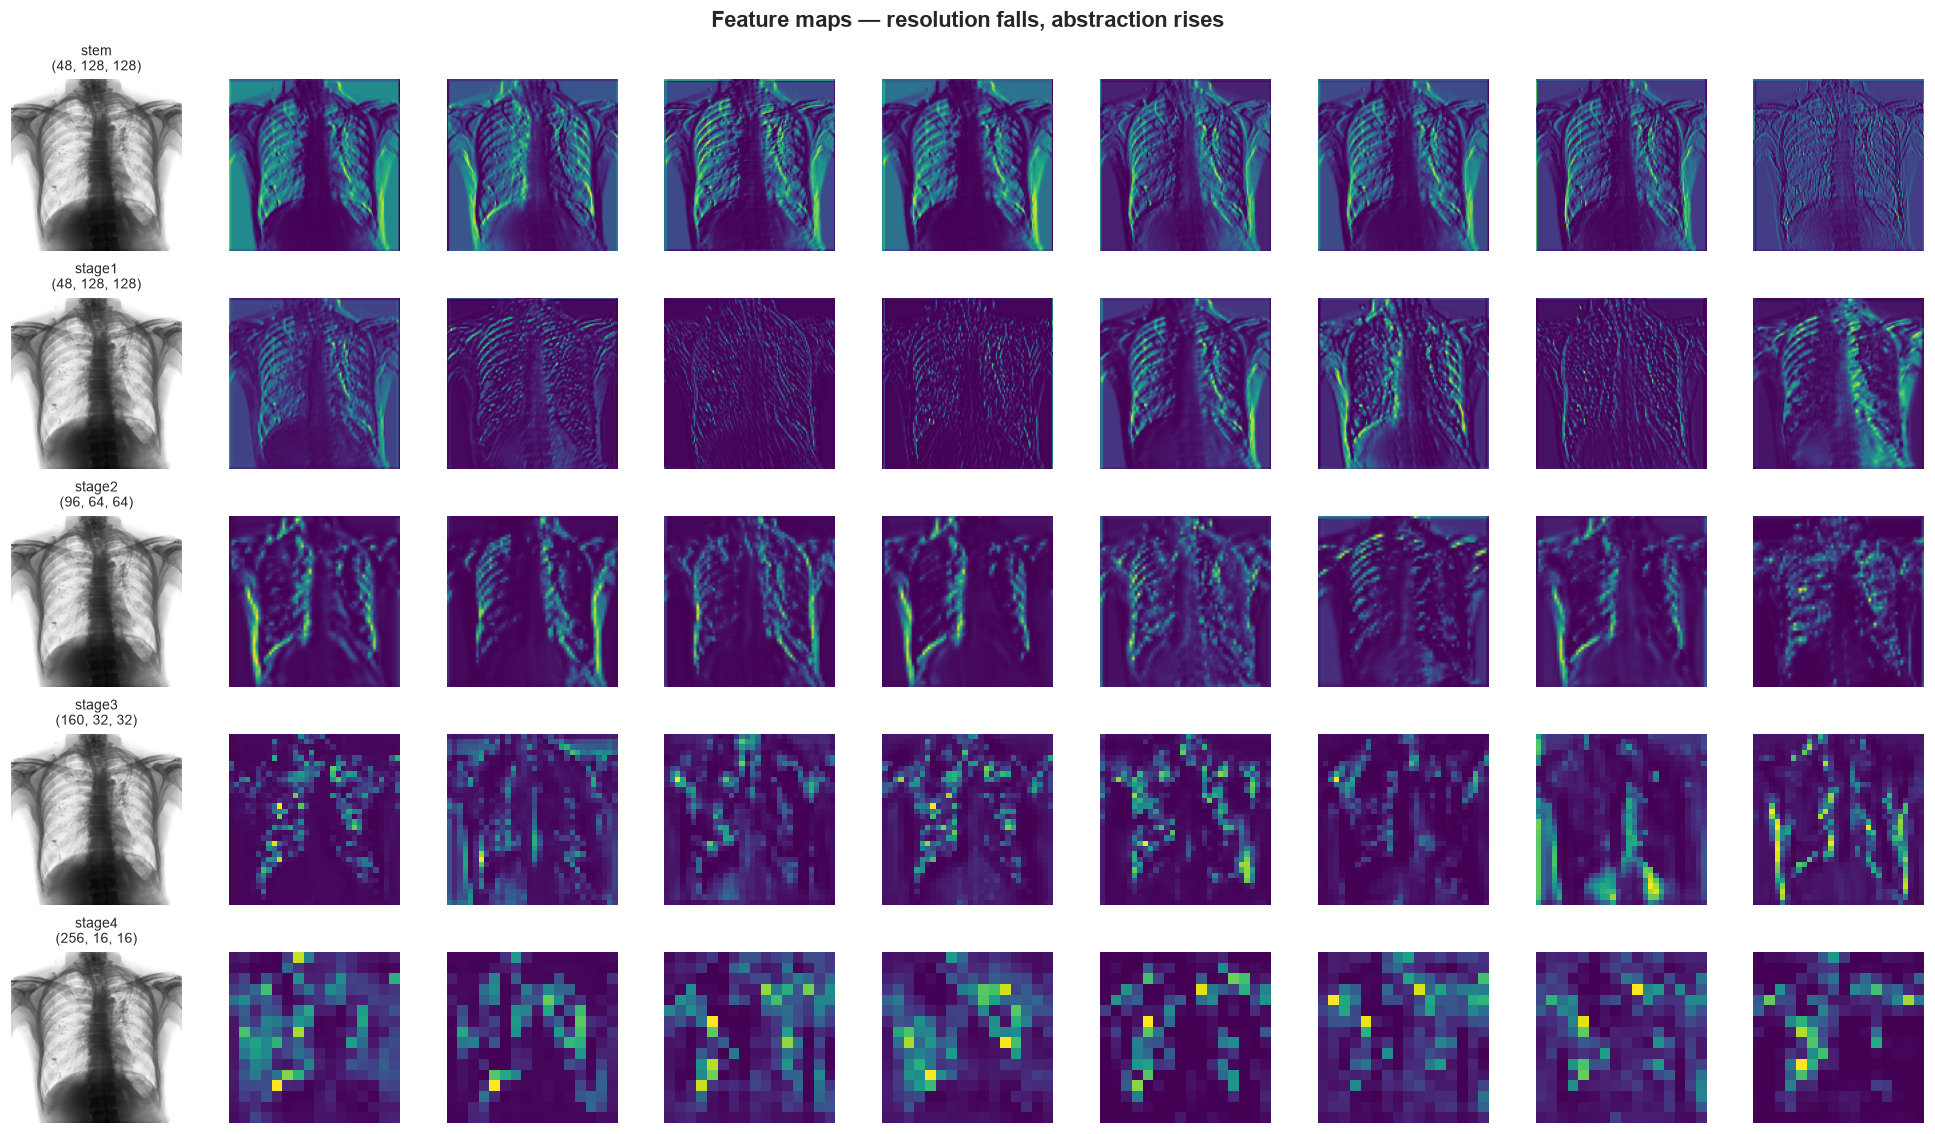

In [12]:
sample = val_df[val_df.label == 1].sample(1, random_state=3).path.iloc[0]
x = prepare_batch(read_xray(ROOT / sample)[None])
model.eval(); maps = {}
with torch.no_grad():
    t = model.stem(x); maps["stem"] = t
    for name in ["stage1", "stage2", "stage3", "stage4"]:
        t = getattr(model, name)(t); maps[name] = t
fig, axes = plt.subplots(5, 9, figsize=(18, 10.5))
for r, (name, fm) in enumerate(maps.items()):
    fm = fm[0].float().cpu()
    axes[r, 0].imshow(read_xray(ROOT / sample)[0], cmap="gray"); axes[r, 0].set_title(f"{name}\n{tuple(fm.shape)}", fontsize=9)
    for c, ch in enumerate(fm.mean((1, 2)).argsort(descending=True)[:8]):
        axes[r, c + 1].imshow(fm[ch], cmap="viridis")
for ax in axes.flat: ax.axis("off")
plt.suptitle("Feature maps — resolution falls, abstraction rises", weight="bold"); plt.tight_layout(); plt.show()

In [13]:
summary = {"arch": "pulmonet", "parameters": count(model), "best_epoch": best["epoch"],
           "best_val_auroc": best["val_auroc"], "train_minutes": train_minutes, "epochs_run": len(history)}
(RUN_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
summary

{'arch': 'pulmonet',
 'parameters': 4085026,
 'best_epoch': 38,
 'best_val_auroc': 0.9245284665163964,
 'train_minutes': 47.56894880135854,
 'epochs_run': 40}